<a href="https://colab.research.google.com/github/Henry6833/Henry6833.github.io/blob/main/Milestone1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#Students' perception of Artificial Intelligence effects on Cognitive Engagement

---



Randall Herrera and Henry Mulvihill

Link to our website: https://henry6833.github.io/

# **Milestone 1**

#**The Project's Goal:**

The team, **Randall Herrera** and **Henry Mulvihill** will be investigating multiple different student's insights on how the use of AI affects their cognitive engagement. We want to showcase the student's learning behaviors with ai and their feedback on cognitive engagement using it. We emphasized searching for survey datasets that asked students the following: frequency usage with AI tools, perceived reliance on it, their perceived effects on critical thinking, and background about the student. We have found two survey datasets that give great measurement and feedback for this project.

# **The Datasets:**

- Our main dataset, [AI Dependency and Academic Vulnerability](https://www.kaggle.com/datasets/mdjhirulislam/ai-dependency-and-academic-vulnerability), contains responses from 1104 college students from Bangladesh. These responses were based on several questions pertaining to how they use Artificial Intelligence tools in academics. The main topics these questions answer are how dependent students are on these tools for learning and whether their usage with cognitive offload is harmful.


- The second dataset we chose, [Study habits and artificial intelligence use among university students](https://data.mendeley.com/datasets/mcwb2ppdsw/1), contains 357 student reponses from Colombian public university. The questions prompted to them were about demographics, study habits, usage of ai in studying, and opinions about using Ai in their studies.

#**Our Collaboration Plan:**

We have decided to meet up for 15 minutes after every Data Science lecture to speak, catch up on ideas to refine, expand, and assist one another's ideas for our approach. We also established a flexible space to meet via Discord every Tuesday or Saturday to inform changes and work simultaneously in the project. Outside of meetings we would commit changes we've made to our GitHub repository independently. After anyone made changes, they would text or call the other one to discuss the new additions to the project.

#**Research Questions**

*   What kind of correlation is shown between students' frequency of AI usage and their perceived reliance with AI.
*   Are students using AI as a tool or an answer key?
* How do students engage with AI to handle complex topics?

In [33]:
import pandas as pd
import numpy as np
import kagglehub
import os
import matplotlib.pyplot as plt

This first cell contains all of the imports that will be required for the code in this project. We will require Pandas for data structures like DataFrames and Series to display the data, and NumPy to perform numerical analysis.


Additionally, Python's built-in os module enables interaction with the operating system: files, folders, and paths within Colab's virtual machine. Other libraries such as mathplotlib help polish our data visualizations and kagglehub will allow us to import our data from Kaggle.

In [34]:
# Download latest version
path = kagglehub.dataset_download("mdjhirulislam/ai-dependency-and-academic-vulnerability")
print("Path to dataset files:", path)

Using Colab cache for faster access to the 'ai-dependency-and-academic-vulnerability' dataset.
Path to dataset files: /kaggle/input/ai-dependency-and-academic-vulnerability


Using the `kagglehub` module imported earlier, we can get the path of one of our datasets directly from Kaggle's API. What kagglehub does is create a new folder to place our dataset, and the `path` variable contains the location of that folder. This is one way for retrieving the data, even if someone who does not have the datasets stored in their computer wishes to access the data.

We might want to learn what the folder that `kagglehub` created contains. `os.listdir(path)` allows us to see everything inside that folder, returned into a Python list. Alternatively, we can run the `!ls` command in the terminal:

In [35]:
os.listdir(path)

['AI Dependency and Academic Vulnerability in Higher Education A Survey Dataset from Bangladesh.csv']

In [36]:
%cd /root/.cache/kagglehub/datasets/mdjhirulislam/ai-dependency-and-academic-vulnerability/versions/1
!ls

/root/.cache/kagglehub/datasets/mdjhirulislam/ai-dependency-and-academic-vulnerability/versions/1
'AI Dependency and Academic Vulnerability in Higher Education A Survey Dataset from Bangladesh.csv'


In this case, we can use the `path` variable to 'build up' the appropriate url based on our system's file directory by passing it as argument to the `os.path.join(...)` function call, where we look up the folder where `kagglehub` originally downloaded the dataset and its name to join them and obtain the full url. The `DataFrame` is ready to be analyzed.

In [37]:
dependency_survey = pd.read_csv(os.path.join(path, "AI Dependency and Academic Vulnerability in Higher Education A Survey Dataset from Bangladesh.csv"))
dependency_survey.head()

,Gender,Age,Name of University,Academic Level,Current CGPA,Daily AI Usage Time,I verify AI-generated information before using it in academic work.,I can study and complete tasks effectively without any AI support.,My first instinct for any academic doubt is to ask an AI rather than checking books or notes.,I find it harder to recall information that I have previously generated using AI.,"When using AI, I prioritize completing assignments quickly rather than fully understanding the subject matter.",I often use AI-generated responses without making any major modifications.,I feel less confident in my writing and analytical skills when I am not using AI.,My critical thinking ability has weakened due to reliance on AI tools.,I often submit academic work without fully understanding the content generated by AI.
0,Male,24-26,Jahangirnagar University,Master's,3.01-3.50,1-3 hours,Disagree,Disagree,Strongly Agree,Agree,Neutral,Agree,Strongly Agree,Strongly Agree,Agree
1,Male,20-23,Daffodil International University,Undergraduate,2.51-3.00,1-3 hours,Strongly Agree,Agree,Neutral,Agree,Disagree,Strongly Agree,Agree,Agree,Strongly Agree
2,Female,20-23,Daffodil International University,Undergraduate,3.01-3.50,1-3 hours,Agree,Neutral,Agree,Disagree,Agree,Disagree,Agree,Agree,Disagree
3,Female,20-23,Daffodil International University,Undergraduate,3.01-3.50,1-3 hours,Agree,Neutral,Neutral,Disagree,Agree,Disagree,Neutral,Strongly Agree,Agree
4,Female,20-23,Primeasia University,Undergraduate,Above 3.50,Less than 1 hour,Agree,Neutral,Neutral,Disagree,Agree,Neutral,Neutral,Disagree,Disagree


We present an alternative method for loading our second dataset:

In [38]:
# Raw urls of the datasets obtained from the data/ folder in the GitHub source repository
url_dataset_1 = "https://raw.githubusercontent.com/Henry6833/Henry6833.github.io/refs/heads/main/data/Dataset%202%20cleaned.csv"

We retrieve the raw url directly from the project's GitHub repository, and store it in a variable. This dataset has a several variables that measure the critical thinking (ct):  
This variable has been simply passed to Pandas' `.read_csv(...)` method to store the dataset as a `DataFrame`.

In [39]:
colombia_survey = pd.read_csv(url_dataset_1)
colombia_survey.head()

,response_date,age_years,gender,non_local_student,current_university_condition,receives_university_support,academic_program,current_program_term,cumulative_gpa_papa,independent_study_time,...,n_ai_tools,ai_use_frequency_for_study,ai_helped_understand_topics,ai_use_in_academic_tasks_is_fraud,failed_evaluated_activity_due_to_ai,verifies_work_with_ai_after_completion,perceived_ai_dependence,perceived_creativity_reduction_from_ai,prompt_engineering_knowledge,uses_ai_for_nonacademic_activities
0,NaN,23,Male,Yes,Full-time student,Yes,Industrial Engineering,9,3.3,3-4,...,5,Almost always,Definitely yes,Disagree,No,Always,Probably yes,Probably yes,Probably yes,Yes
1,NaN,19,Male,Yes,Study and work,No,Computer Science,5,4.4,More than 5,...,4,Almost always,Definitely yes,Undecided,No,Rarely,Probably not,Not at all,Not at all,Yes
2,NaN,21,Male,Yes,Full-time student,Yes,Computer Science,7,4.0,3-4,...,4,Always,Definitely yes,Undecided,Yes,Almost always,A lot,Not at all,Probably yes,Yes
3,NaN,22,Female,Yes,Study and work,Yes,Industrial Engineering,8,4.3,More than 5,...,7,Almost always,Definitely yes,Strongly disagree,No,Occasionally,Probably yes,Probably not,Probably yes,Yes
4,NaN,19,Female,No,Full-time student,Yes,Statistics,3,4.0,4-5,...,4,Almost always,Probably yes,Strongly disagree,No,Always,Probably yes,Probably not,Probably not,Yes


# **Data Tidying (Dataset 1):**
The first principle of Data Tidying says that each variable forms a column and has values. While the `dependency_survey` dataset satisfies this principle, the variables names are full sentences for the questions, rather than concise names that capture a concrete feature for an observation. In `dependency_survey`, an observation represents a student that filled the form. We modify the column names to be more readable:   
The `codebook` variable simply allows us to map the new column's name with the corresponding question from the survey.

In [40]:
original_columns = dependency_survey.columns.tolist()

new_cols = ["gender", "age_group", "university", "academic_level", "current_cgpa",
            "daily_ai_use", "verifies_ai_output", "can_study_without_ai",
            "ai_first_instinct", "harder_recall_ai_content", "speed_over_understanding",
            "uses_ai_unedited", "less_confident_without_ai", "ct_weakened",
            "submits_without_understanding"]

codebook = dict(zip(new_cols, original_columns))
codebook["speed_over_understanding"]

'When using AI, I prioritize completing assignments quickly rather than fully understanding the subject matter.'

Now, we simply renamed our columns. This way, the data table looks less cluttered, and the new variables from our columns successfully describe all features of each observation. We can also assert whether the dataset is missing values:

In [41]:
dependency_survey.columns = new_cols
dependency_survey.head()

,gender,age_group,university,academic_level,current_cgpa,daily_ai_use,verifies_ai_output,can_study_without_ai,ai_first_instinct,harder_recall_ai_content,speed_over_understanding,uses_ai_unedited,less_confident_without_ai,ct_weakened,submits_without_understanding
0,Male,24-26,Jahangirnagar University,Master's,3.01-3.50,1-3 hours,Disagree,Disagree,Strongly Agree,Agree,Neutral,Agree,Strongly Agree,Strongly Agree,Agree
1,Male,20-23,Daffodil International University,Undergraduate,2.51-3.00,1-3 hours,Strongly Agree,Agree,Neutral,Agree,Disagree,Strongly Agree,Agree,Agree,Strongly Agree
2,Female,20-23,Daffodil International University,Undergraduate,3.01-3.50,1-3 hours,Agree,Neutral,Agree,Disagree,Agree,Disagree,Agree,Agree,Disagree
3,Female,20-23,Daffodil International University,Undergraduate,3.01-3.50,1-3 hours,Agree,Neutral,Neutral,Disagree,Agree,Disagree,Neutral,Strongly Agree,Agree
4,Female,20-23,Primeasia University,Undergraduate,Above 3.50,Less than 1 hour,Agree,Neutral,Neutral,Disagree,Agree,Neutral,Neutral,Disagree,Disagree


In [42]:
dependency_survey.isna().sum()

,0
gender,0
age_group,0
university,0
academic_level,0
current_cgpa,0
daily_ai_use,0
verifies_ai_output,0
can_study_without_ai,0
ai_first_instinct,0
harder_recall_ai_content,0


Our dataset has no missing values (NaN) for any of the variables. This makes sense, as the data comes from a survey, and the questions were mandatory. This implies, every student, the observational unit represented by one row of `dependency_survey` dataset answered all of the questions.

In [43]:
dependency_survey.duplicated().sum()

np.int64(162)

The dataset contains 162 rows that are identical across all variables! This could originally imply that there are 162 duplicated entries. However, the dataset does not provide a unique respondent identifier. It could be the case that either a respondent took the survey twice, or different participants selected the same responses. It could also be the case that a participant responded twice or multiple times, and selected a different answer for some variable in each attempt.

# **Data Tidying(Dataset 2):**

We notice the column **response_date** contains only NaN values that will only clutter our dataset. we will remove it for this reason.

In [44]:
if "response_date" in colombia_survey.columns:
  response_date_nan = colombia_survey["response_date"].isna().sum()
  total_response_date_val = len(colombia_survey["response_date"])

if response_date_nan == total_response_date_val:
  print(f"number of NaN values in response_date: {response_date_nan} == {total_response_date_val} number of total values")

else:
  print(f"number of NaN values in response_date: {response_date_nan} != {total_response_date_val} number of total values")

colombia_survey.drop(columns="response_date",errors="ignore",inplace=True)
colombia_survey.head()

number of NaN values in response_date: 357 == 357 number of total values


,age_years,gender,non_local_student,current_university_condition,receives_university_support,academic_program,current_program_term,cumulative_gpa_papa,independent_study_time,organizes_notes_before_tests,...,n_ai_tools,ai_use_frequency_for_study,ai_helped_understand_topics,ai_use_in_academic_tasks_is_fraud,failed_evaluated_activity_due_to_ai,verifies_work_with_ai_after_completion,perceived_ai_dependence,perceived_creativity_reduction_from_ai,prompt_engineering_knowledge,uses_ai_for_nonacademic_activities
0,23,Male,Yes,Full-time student,Yes,Industrial Engineering,9,3.3,3-4,Almost always,...,5,Almost always,Definitely yes,Disagree,No,Always,Probably yes,Probably yes,Probably yes,Yes
1,19,Male,Yes,Study and work,No,Computer Science,5,4.4,More than 5,Almost always,...,4,Almost always,Definitely yes,Undecided,No,Rarely,Probably not,Not at all,Not at all,Yes
2,21,Male,Yes,Full-time student,Yes,Computer Science,7,4.0,3-4,Always,...,4,Always,Definitely yes,Undecided,Yes,Almost always,A lot,Not at all,Probably yes,Yes
3,22,Female,Yes,Study and work,Yes,Industrial Engineering,8,4.3,More than 5,Always,...,7,Almost always,Definitely yes,Strongly disagree,No,Occasionally,Probably yes,Probably not,Probably yes,Yes
4,19,Female,No,Full-time student,Yes,Statistics,3,4.0,4-5,Always,...,4,Almost always,Probably yes,Strongly disagree,No,Always,Probably yes,Probably not,Probably not,Yes


# **Dtypes and Statistical Data Types (Dataset 1):**

The `dtype` for this dataset is `object` for all variables, which immediately implies the data is categorical. This is true in many cases, but pandas fails to interpret the statistical data type in many other. We provide a deeper insight:

In [45]:
dependency_survey.dtypes

,0
gender,object
age_group,object
university,object
academic_level,object
current_cgpa,object
daily_ai_use,object
verifies_ai_output,object
can_study_without_ai,object
ai_first_instinct,object
harder_recall_ai_content,object


All these variables' type is **ordinal**. `academic_level` suggests there is some order between the categories `'Undergraduate'`, `'Master's'` ,`'Graduate'`. The rest of the columns in this `DataFrame` after `verifies_ai_output` are also **ordinal** because categories like `Agree` and `Strongly Agree` imply there is an order between the two.

In [46]:
display(dependency_survey[
    ["academic_level"] +
    dependency_survey.loc[:, "verifies_ai_output":].columns.tolist()
].head())
dependency_survey["academic_level"].unique()

,academic_level,verifies_ai_output,can_study_without_ai,ai_first_instinct,harder_recall_ai_content,speed_over_understanding,uses_ai_unedited,less_confident_without_ai,ct_weakened,submits_without_understanding
0,Master's,Disagree,Disagree,Strongly Agree,Agree,Neutral,Agree,Strongly Agree,Strongly Agree,Agree
1,Undergraduate,Strongly Agree,Agree,Neutral,Agree,Disagree,Strongly Agree,Agree,Agree,Strongly Agree
2,Undergraduate,Agree,Neutral,Agree,Disagree,Agree,Disagree,Agree,Agree,Disagree
3,Undergraduate,Agree,Neutral,Neutral,Disagree,Agree,Disagree,Neutral,Strongly Agree,Agree
4,Undergraduate,Agree,Neutral,Neutral,Disagree,Agree,Neutral,Neutral,Disagree,Disagree


array(["Master's", 'Undergraduate', 'Graduate'], dtype=object)

The variables `age_group`, `current_cgpa` and `daily_ai_use` might look like interval, because they are measured in an interval scale involving numbers. In reality, they are **ordinal**, because they involve non-numeric characters like "-", "Less than", but there is a relation or rank. For example "Less than 1 hour" is less than "1-3 hours". "3.01-3.5" < "Above 3.5". The differences and sums are meaningless because we don't have fixed values, so they don't make sense. Therefore, Pandas' `object` is accurate in this case.

In [47]:
dependency_survey[["age_group", "current_cgpa", "daily_ai_use"]].head()

,age_group,current_cgpa,daily_ai_use
0,24-26,3.01-3.50,1-3 hours
1,20-23,2.51-3.00,1-3 hours
2,20-23,3.01-3.50,1-3 hours
3,20-23,3.01-3.50,1-3 hours
4,20-23,Above 3.50,Less than 1 hour


Finally, the `gender` and `university` variables are Nominal because categories like `Male`, `Female`, or any university name have no meaningful ordering within their respective categories.

In [48]:
dependency_survey[["gender", "university"]].head()

,gender,university
0,Male,Jahangirnagar University
1,Male,Daffodil International University
2,Female,Daffodil International University
3,Female,Daffodil International University
4,Female,Primeasia University


We replace the labels and dtypes of our values from each column containing ordinal data. This will be useful for the EDA part of our project.

In [49]:
mapping ={
    "Strongly Disagree": 1,
    "Disagree": 2,
    "Neutral":3,
    "Agree":4,
    "Strongly Agree":5
}
start_index = dependency_survey.columns.get_loc("verifies_ai_output")
for col in dependency_survey.columns[start_index:]:
  dependency_survey[col] = dependency_survey[col].map(mapping)
dependency_survey.head()

,gender,age_group,university,academic_level,current_cgpa,daily_ai_use,verifies_ai_output,can_study_without_ai,ai_first_instinct,harder_recall_ai_content,speed_over_understanding,uses_ai_unedited,less_confident_without_ai,ct_weakened,submits_without_understanding
0,Male,24-26,Jahangirnagar University,Master's,3.01-3.50,1-3 hours,2,2,5,4,3,4,5,5,4
1,Male,20-23,Daffodil International University,Undergraduate,2.51-3.00,1-3 hours,5,4,3,4,2,5,4,4,5
2,Female,20-23,Daffodil International University,Undergraduate,3.01-3.50,1-3 hours,4,3,4,2,4,2,4,4,2
3,Female,20-23,Daffodil International University,Undergraduate,3.01-3.50,1-3 hours,4,3,3,2,4,2,3,5,4
4,Female,20-23,Primeasia University,Undergraduate,Above 3.50,Less than 1 hour,4,3,3,2,4,3,3,2,2


# **Dtypes and Statistical Data Types (Dataset 2):**

We find that the ```dtypes``` contained in this dataset are **int64**,**object**, and **float64**. Although we've found every kind of dtype in this dataset, we are not sure if some are ``nominal`` or ```ordinal``` for the **objects**. Furthermore, we are not sure whether some **float64** or **int64** dtypes are ```interval``` or ```ratio```. We will need to look deeper to figure this out.  

In [50]:
colombia_survey.dtypes

,0
age_years,int64
gender,object
non_local_student,object
current_university_condition,object
receives_university_support,object
academic_program,object
current_program_term,int64
cumulative_gpa_papa,float64
independent_study_time,object
organizes_notes_before_tests,object


We will begin with the majority dtype **object**. Using pandas ```select_dtypes``` we can look at every column with **object** dtype values. This allows us to see if any values have an ordering among them. If we find any ordering does exist, we can conlude it is ```ordinal``` and if not it is ```nominal```. Since the dataframe's column ordering is ambiguous, showing every column's possible values gives us a clear picture on what is ```nominal``` and ```ordinal```. From our display we find ```gender```, ```non_local_student```, ```current_university_condition```, ```academic_program```,```ai_tools_raw```,```ai_tools_standardized```, ```failed_evaluated_activity_due_to_ai```, and ```uses_ai_for_nonacademic_activities``` are all **nominal**. The rest of our columns have an inherent ordering between them which implies they are **ordinal**.

In [51]:
object_list = colombia_survey.select_dtypes(include="object").columns

for column in object_list:
  if column == "ai_tools_raw" or column == "ai_tools_standardized":
    print(f"{column}: {colombia_survey[column].nunique()}")

  else:
    print(f"{column}: {colombia_survey[column].unique()}")

gender: ['Male' 'Female']
non_local_student: ['Yes' 'No']
current_university_condition: ['Full-time student' 'Study and work']
receives_university_support: ['Yes' 'No']
academic_program: ['Industrial Engineering' 'Computer Science' 'Statistics'
 'Electronic Engineering' 'Business Administration' 'Mathematics'
 'Chemical Engineering' 'Information Systems Administration'
 'Engineering Physics' 'Civil Engineering' 'Electrical Engineering'
 'Architecture' 'Cultural and Communication Management'
 'Biological Engineering']
independent_study_time: ['3-4' 'More than 5' '4-5' '2-3' '1-2' '0-1']
organizes_notes_before_tests: ['Almost always' 'Always' 'Occasionally' 'Rarely' 'Never']
study_method_effectiveness: ['Neutral' 'Very effective' 'Effective' 'Slightly effective'
 'Not effective at all']
uses_supplementary_resources: ['Almost always' 'Always' 'Occasionally' 'Rarely' 'Never']
procrastination_frequency: ['Occasionally' 'Almost always' 'Rarely' 'Always' 'Never']
study_groups_or_tutoring: ['R

We can apply the same method for the rest of our data types **int64** and **float64**. ```current_program_term``` is ```ordinal``` due to the fact a higher term value implies more experience. ```cumulative_gpa_papa``` is ```interval``` since we can find a difference between gpas but not an absolute zero. ```age_years``` and ```n_ai_tools``` are ```ratio``` since they both possess an absolute zero.

In [52]:
num_list = colombia_survey.select_dtypes(include=["int64","float64"])
num_list.head()

,age_years,current_program_term,cumulative_gpa_papa,n_ai_tools
0,23,9,3.3,5
1,19,5,4.4,4
2,21,7,4.0,4
3,22,8,4.3,7
4,19,3,4.0,4


Now that we have defined our statistical data types we want to convert our ordinal data's values from strings to ints. We will start by creating the dictionaries and lists to set up the mapping.

In [53]:
frequency_map = {
    "Never": 1,
    "Rarely": 2,
    "Occasionally": 3,
    "Almost always": 4,
    "Always": 5
}

frequency_val = ["Never","Rarely","Occasionally","Almost always","Always"]

Agreement_map = {
    "Not at all": 1,
    "Probably not": 2,
    "Not sure": 3,
    "Probably yes": 4,
    "A lot": 5
}

Aggrement_val = ["Not at all","Probably not","Not sure","Probably yes","A lot"]

Effectiveness_map = {
    "Not effective at all": 1,
    "Slightly effective": 2,
    "Neutral": 3,
    "Effective": 4,
    "Very effective": 5
}

Effectiveness_val = ["Not effective at all","Slightly effective","Neutral","Effective","Very effective"]

Academic_map = {
    "Poor": 1,
    "Fair": 2,
    "Good": 3,
    "Excellent": 4,
    "Outstanding": 5
}

Academic_val = ["Poor","Fair","Good","Excellent","Outstanding"]

Helpful_map = {
    "Definitely no": 1,
    "Probably no": 2,
    "Neutral": 3,
    "Probably yes": 4,
    "Definitely yes": 5
}

Helpful_val = ["Definitely no","Probably no","Neutral","Probably yes","Definitely yes"]

Opinion_map = {
    "Strongly disagree": 1,
    "Disagree": 2,
    "Undecided": 3,
    "Agree": 4,
    "Strongly agree": 5
}

Opinion_val = ["Strongly disagree","Disagree","Undecided","Agree","Strongly agree"]

Study_map = {
    "0-1": 1,
    "1-2": 2,
    "2-3": 3,
    "3-4": 4,
    "4-5": 5,
    "More than 5": 6
}

Study_val = ["0-1","1-2","2-3","3-4","4-5","More than 5"]

Binary_map = {
    "Yes":1,
    "No": 0

}

Gender_map = {
    "Male": 1,
    "Female": 0
}

Condition_map = {
    "Full-time student": 1,
    "Study and work": 0
}

all_maps = [frequency_map, Agreement_map, Effectiveness_map,Academic_map, Helpful_map, Opinion_map, Study_map, Binary_map, Gender_map, Condition_map]

Now we create the mapping through a nested for loop. This will make our EDA part of this data much easier.

In [54]:
#Disclaimer! Gemini was used to assist with this part of the code

for col in object_list:
    col_set = set(colombia_survey[col].unique()) #makes the numpy array into a set to allow no duplicates
    for m in all_maps: #iterate over all the maps
        if col_set.issubset(m.keys()): #checks if the set is a subset of the keys in a specified map
            colombia_survey[col] = colombia_survey[col].map(m) #maps according to the specific column
            break
colombia_survey

,age_years,gender,non_local_student,current_university_condition,receives_university_support,academic_program,current_program_term,cumulative_gpa_papa,independent_study_time,organizes_notes_before_tests,...,n_ai_tools,ai_use_frequency_for_study,ai_helped_understand_topics,ai_use_in_academic_tasks_is_fraud,failed_evaluated_activity_due_to_ai,verifies_work_with_ai_after_completion,perceived_ai_dependence,perceived_creativity_reduction_from_ai,prompt_engineering_knowledge,uses_ai_for_nonacademic_activities
0,23,1,1,1,1,Industrial Engineering,9,3.3,4,4,...,5,4,5,2,0,5,4,4,4,1
1,19,1,1,0,0,Computer Science,5,4.4,6,4,...,4,4,5,3,0,2,2,1,1,1
2,21,1,1,1,1,Computer Science,7,4.0,4,5,...,4,5,5,3,1,4,5,1,4,1
3,22,0,1,0,1,Industrial Engineering,8,4.3,6,5,...,7,4,5,1,0,3,4,2,4,1
4,19,0,0,1,1,Statistics,3,4.0,5,5,...,4,4,4,1,0,5,4,2,2,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
352,19,0,0,0,0,Business Administration,5,4.0,4,4,...,5,4,5,3,0,4,2,4,4,1
353,23,1,0,1,0,Business Administration,9,3.8,5,3,...,2,3,5,3,0,4,3,3,2,1
354,24,1,0,0,0,Business Administration,8,3.9,3,4,...,3,4,4,3,1,5,3,3,3,1
355,23,0,1,0,0,Information Systems Administration,11,4.0,3,5,...,3,3,5,2,0,4,3,4,2,1


# **EDA (Exploratory Analysis):**

We begin our analysis by finding the frequency distribution between all students frequency usage with AI and if they can study without it.

In [55]:
dependency_show = dependency_survey.pivot_table(index="can_study_without_ai",values="academic_level",columns="daily_ai_use",aggfunc="count")
dependency_show

daily_ai_use,1-3 hours,Less than 1 hour,More than 3 hours
can_study_without_ai,,,
1,26,4,106
2,125,35,253
3,78,19,43
4,56,238,48
5,6,59,8


Pivot table ```dependency_show``` allows us to compare the students with ```can_study_without_ai``` as index, with ```daily_ai_use```. This gives us a new perspective on the relationship between the frequency students use AI and how much they rely on it. It also deepens our understanding if students can solve problems or learn without AI assistance.

In [56]:
ordinal_data = dependency_survey.columns.get_loc("verifies_ai_output")
summary_table = dependency_survey.iloc[:, ordinal_data:].apply(lambda col: col.value_counts())
display(summary_table)

,verifies_ai_output,can_study_without_ai,ai_first_instinct,harder_recall_ai_content,speed_over_understanding,uses_ai_unedited,less_confident_without_ai,ct_weakened,submits_without_understanding
1,80,136,36,51,37,35,60,54,163
2,475,413,300,262,266,272,263,237,161
3,117,140,114,158,181,199,169,174,120
4,398,342,462,444,453,446,488,480,347
5,34,73,192,189,167,152,124,159,313


Shown here is the frequency distribution for each column ranging from 1 (`Strongly Disagree`) to 5 (`Strongly Agree`). This gives us insight on the overall approaches students utilize with AI. From this, we have an idea for the "dominant" agreement among each column. For example we can see that the most frequent response from `speed_over_understanding` is `Agree`. But looking at another column such as `verifies_ai_output`, we see that `Disagree` is the most frequent value.

(0.0, 100.0)

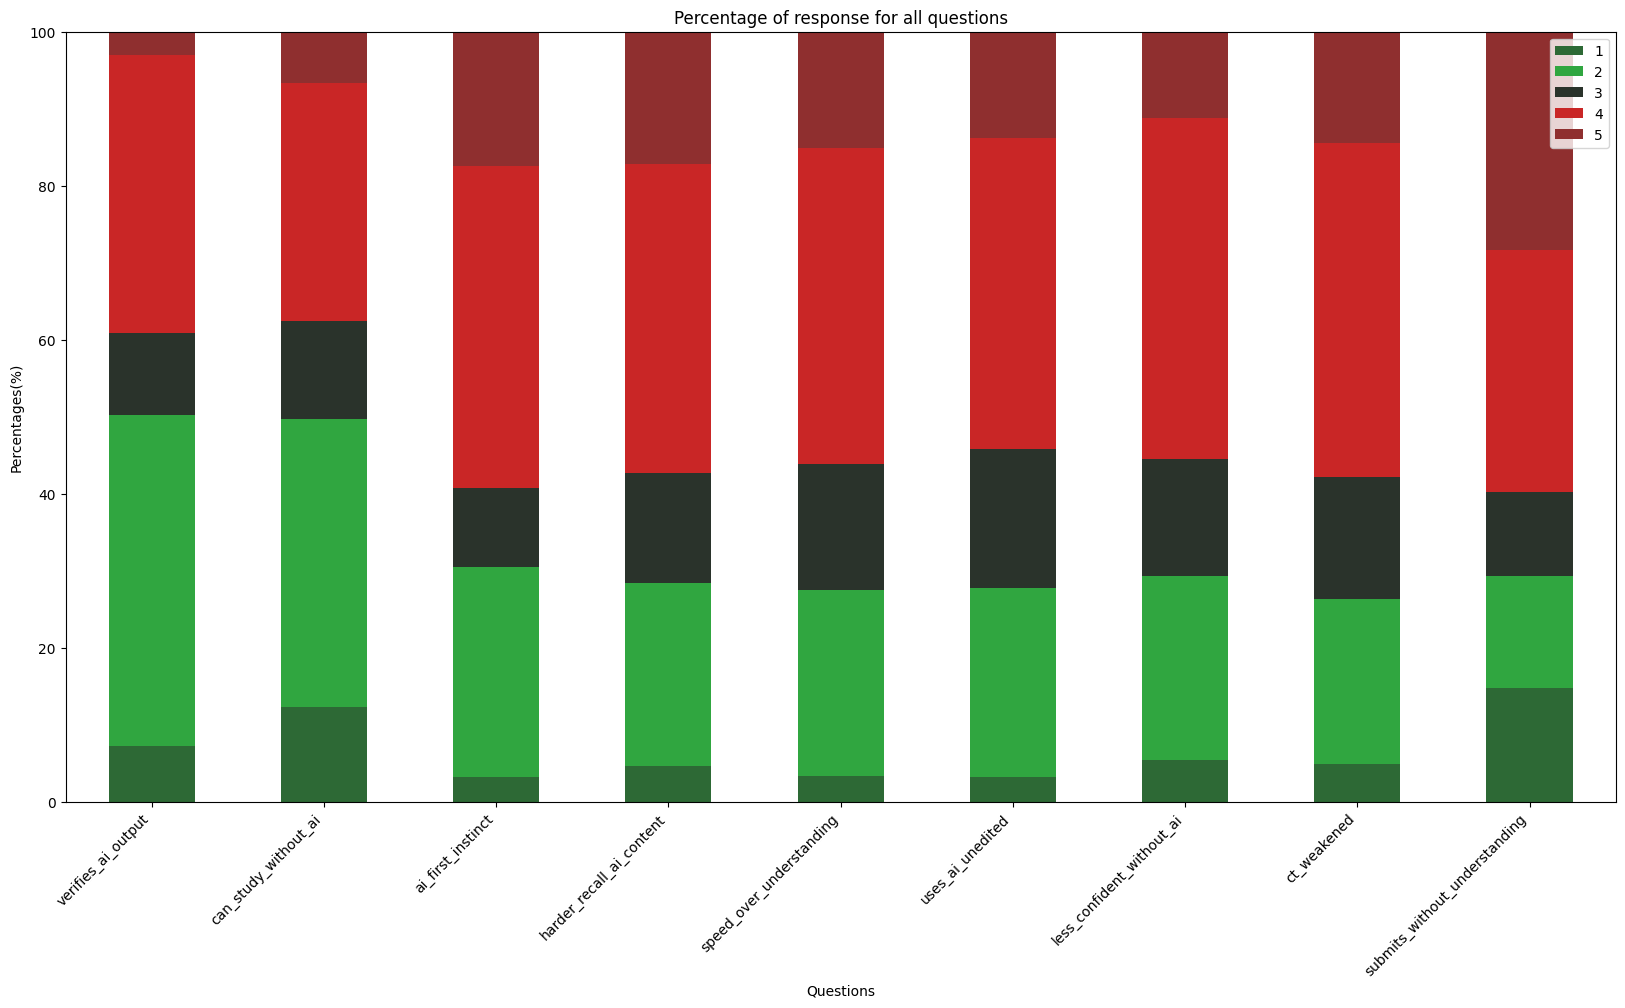

In [57]:
ordinal_data = dependency_survey.columns.get_loc("verifies_ai_output")
percent_summary = dependency_survey.iloc[:,ordinal_data:].apply(lambda col:col.value_counts(normalize=True)*100)
percent_summary.T.plot(kind="bar",stacked=True,figsize=(20,10),color=["#2d6935","#30a640","#2a332b","#c92626","#8f2f2f"])
plt.title("Percentage of response for all questions")
plt.xlabel("Questions")
plt.ylabel("Percentages(%)")
plt.xticks(rotation=45,ha="right")
plt.ylim(0, 100)

A stacked bar chart is best to use since our data is on a likert scale. This chart shows the percentage of each agreement for each question. We can use this visualization to showcase what percentage of students agree or disagree with certain prompts. Specific distribution for prompts such as ai_first_instinct and speed_over_understanding give us deeper insight on how student engage with topics when using AI. These findings lead us closer to configuring an idea on student's behavioral mechanisms using AI.



In [58]:
dependency_survey.verifies_ai_output

,verifies_ai_output
0,2
1,5
2,4
3,4
4,4
...,...
1099,3
1100,2
1101,2
1102,2


Another interesting statistic, would be to analyze the habits of students, which involve their daily usage of AI tools and whether they verify or not the LLM's output's quality before using it. We can use these features to see whether these habits matter on whether who many students in these groups perceive their critical thinking decreased.

In [59]:
habits = dependency_survey.assign(ct_weakened_agree =dependency_survey["ct_weakened"] >= 4,
verifier=np.where(dependency_survey["verifies_ai_output"] >= 4, "Verifies output", "Does not verify output"))
usage_habits = habits.groupby(["daily_ai_use", "verifier"], observed=True)["ct_weakened_agree"].agg(["mean", "size"])
usage_habits = usage_habits.rename(columns={"mean": "proportion_agree", "size": "count"})
usage_habits

proportion_agree  count
daily_ai_use      verifier                                       
1-3 hours         Does not verify output          0.654709    223
                  Verifies output                 0.617647     68
Less than 1 hour  Does not verify output          0.727273     55
                  Verifies output                 0.100000    300
More than 3 hours Does not verify output          0.875635    394
                  Verifies output                 0.562500     64

We can see that among students using AI less than 1 hour a day, ~73% (55) of those who do not verify agree, compared to ~10% (300) of those who do. In the `1-3 hours` group, the two are nearly the same: ~62% and ~65% for verifies and does not verify respectively. Finally, among students with heavier daily use, ~86% do not verify the output, compared to 56% of students who verify. This can be appreciated in the bar chart below.

(0.0, 1.0)

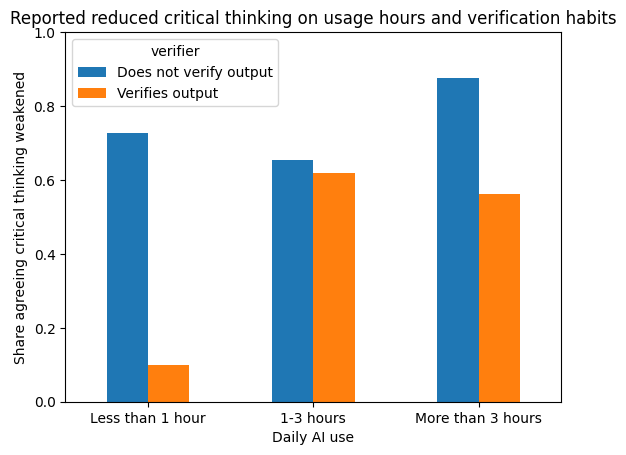

In [60]:
plot_data = usage_habits["proportion_agree"].unstack()
plot_data = plot_data.reindex(["Less than 1 hour", "1-3 hours", "More than 3 hours"])

ax = plot_data.plot(kind="bar", rot=0)
ax.set_ylabel("Share agreeing critical thinking weakened")
ax.set_xlabel("Daily AI use")
ax.set_title("Reported reduced critical thinking on usage hours and verification habits")
ax.set_ylim(0,1)

# **Next steps:**
- The `codebook` variable maps each of the new columns of `dependency_survey` with the original question they answer. As we do further analysis in future milestones for our project, it serves as a reference that will allow us to come up with a hypothesis or model that makes our answer to our research question more concrete.

- Additionally, the `dependency_survey` dataset is said to be intended to support research on predictive modeling, academic behavior analysis and AI-driven educational decision making. We look forward to be able to use this data, alongside the `colombia_survey` dataset to develop a decision tree model that is able to classify whether a student's AI usage produced positive or negative effects on their cognitive engagement. We plan to feed this model mainly with the variables from `dependency_survey` as features, and classify by whether they consider they critical thinking has been weakened by their usage of AI.

- We need to define what an 'optimal decision' would be, based on these habits we are taking as variables. This question will guide our upcoming steps for the next milestone of this project.



In [61]:
#%%shell
#jupyter nbconvert --to html "/content/drive/MyDrive/Colab Notebooks/DataSci_Project.ipynb"

# **Milestone 2:**

A new dataset has been loaded, and replaced the previously unused dataset, which now contains this new dataset. This dataset, also known above as "**Dataset 2**", has been loaded and tidied. This milestone will be mostly focused on this dataset, now stored on the `colombia_survey` variable, but we will still go back to `dependency_survey`from Milestone 1 for analysis and comparison.

In [63]:
colombia_survey.columns

Index(['age_years', 'gender', 'non_local_student',
       'current_university_condition', 'receives_university_support',
       'academic_program', 'current_program_term', 'cumulative_gpa_papa',
       'independent_study_time', 'organizes_notes_before_tests',
       'study_method_effectiveness', 'uses_supplementary_resources',
       'procrastination_frequency', 'study_groups_or_tutoring',
       'self_rated_academic_performance', 'satisfaction_with_grades',
       'career_satisfaction_affects_motivation', 'program_meets_expectations',
       'ai_tools_raw', 'ai_tools_standardized', 'n_ai_tools',
       'ai_use_frequency_for_study', 'ai_helped_understand_topics',
       'ai_use_in_academic_tasks_is_fraud',
       'failed_evaluated_activity_due_to_ai',
       'verifies_work_with_ai_after_completion', 'perceived_ai_dependence',
       'perceived_creativity_reduction_from_ai',
       'prompt_engineering_knowledge', 'uses_ai_for_nonacademic_activities'],
      dtype='object')

With the second dataset, `colombia_survey` loaded, we explore the relationship between AI usage and depenence. Does more use is related to more dependence?

To measure high dependence, we want to keep track of who agrees on perceiving AI dependence. Thus, we choose the column `perceived_ai_dependence` in `colombia_survey` as our measure for high dependence, and we group by `ai_use_frequency_for_study`.

In [65]:
colombia_survey["high_dependence"] = colombia_survey["perceived_ai_dependence"] >= 4

dependence_by_use_colombia = colombia_survey.groupby("ai_use_frequency_for_study")["high_dependence"].agg(["mean", "size"])
dependence_by_use_colombia

,mean,size
ai_use_frequency_for_study,,
1,0.000000,2
2,0.035714,28
3,0.192661,109
4,0.433962,159
5,0.711864,59


Note that nobody in the `colombia_survey` does **never** use AI. We choose `can_study_without_ai` to measure high AI usage, and group by `daily_ai_use`. The goal is to establish a comparison between the use-dependence relationship we find in both `colombia_survey` and `dependency_survey`:

In [74]:
dependency_survey["high_dependence"] = dependency_survey["can_study_without_ai"] <= 2   # To denote higher dependence, since this implies students consider they cannot study without AI

dependence_by_use_dependency = dependency_survey.groupby("daily_ai_use")["high_dependence"].agg(["mean", "size"])
dependence_by_use_dependency = dependence_by_use_dependency.reindex(["Less then 1 hour", "1-3 hours", "More than 3 hours"])  # We reindex so the data doesn't look weird when plotting
dependence_by_use_dependency

,mean,size
daily_ai_use,,
Less then 1 hour,NaN,NaN
1-3 hours,0.518900,291.0
More than 3 hours,0.783843,458.0


Similarly, nobody in `dependency_survey` uses AI for less than one hour. The following bar charts show how the dependence on AI with respect to our chosen measures for high-usage:

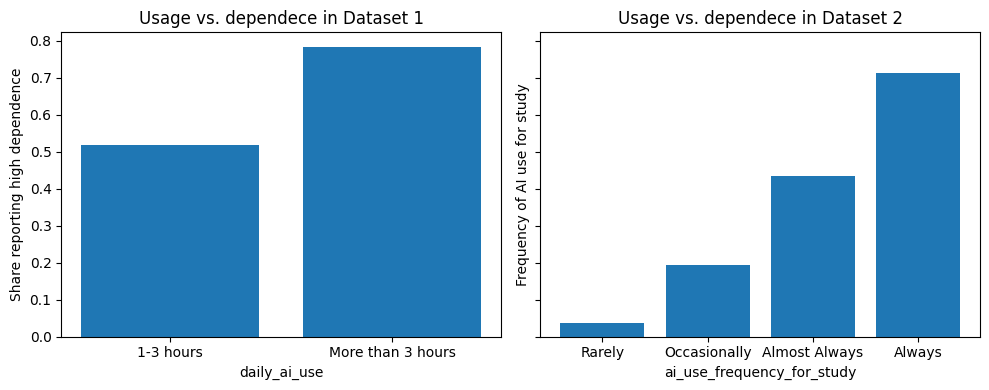

In [81]:
fig, axes = plt.subplots(1,2, figsize=(10,4), sharey=True)

axes[0].bar(dependence_by_use_dependency.index, dependence_by_use_dependency["mean"])
axes[0].set_title("Usage vs. dependece in Dataset 1")
axes[0].set_xlabel("daily_ai_use")
axes[0].set_ylabel("Share reporting high dependence")

colombia_plot = dependence_by_use_colombia.loc[2:5]  # There is nobody that doesn't use AI, we simply ignore the first row.
axes[1].bar(["Rarely", "Occasionally", "Almost Always", "Always"], colombia_plot["mean"])
axes[1].set_title("Usage vs. dependece in Dataset 2")
axes[1].set_xlabel("ai_use_frequency_for_study")
axes[1].set_ylabel("Frequency of AI use for study")

plt.tight_layout()
plt.show()

We notice that our measures for perceived dependence are higher in an ascending order on the corresponing measure for AI usage time. This implies that there is a positive correlation between usage and dependence.